# CART: Classification and Regression Trees

This notebook brings both CART workflows together: wine cultivar classification and synthetic house-price regression. Each includes data exploration, a full tree, pre-pruning, post-pruning, cross-validation, held-out evaluation, interpretation, and a new prediction.

## How to run

Use a Python environment with `numpy`, `pandas`, `matplotlib`, `scikit-learn`, and `ipykernel` installed. Run the shared setup first, then run the cells in either part in order, or use **Restart Kernel and Run All Cells** for the complete workflow. No dataset download is needed.

Variables use `clf_` for classification and `reg_` for regression so both workflows remain available in the same kernel.

- [Shared setup](#shared-setup)
- [Part 1: Classification](#classification)
- [Part 2: Regression](#regression)
- [CART comparison](#cart-comparison)


<a id="shared-setup"></a>
## Shared setup

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_wine
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, KFold, GridSearchCV, cross_val_score
)
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, log_loss,
    classification_report, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)

RANDOM_STATE = 42
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False,
                     'axes.spines.right': False})
np.set_printoptions(precision=4, suppress=True)


<a id="classification"></a>
## Part 1: CART Classification: Wine Cultivar Prediction

**Goal:** predict one of three wine cultivars from chemical measurements, using a Classification and Regression Tree (CART). We use scikit-learn's bundled Wine dataset: 178 observations, 13 numeric features, and three classes. It requires no download and provides a more useful evaluation exercise than the 14-row Tennis dataset.

**Workflow:** inspect data → stratified train/test split → full tree → pre-pruning → post-pruning → training-only model selection → held-out evaluation → interpretation and a new prediction.

CART classification uses **binary splits**, even for a three-class target. A split reduces Gini impurity, $G = 1 - \sum_k p_k^2$. Leaves predict the majority class; their class proportions provide probability estimates. Regression trees instead predict a numeric value, typically the leaf mean.

### 1. Load and inspect the dataset

Each row describes a wine sample using laboratory measurements. Class labels identify cultivars, not a quality ranking. We retain the dataset's `class_0`, `class_1`, and `class_2` names. Numeric inputs need neither categorical encoding nor feature scaling for a decision tree.

Source: the Wine dataset bundled with `sklearn.datasets.load_wine`; its description and provenance are available in `wine.DESCR`.

178 samples | 13 numeric features | 3 classes


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,class_0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,class_0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,class_0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


Missing values: 0
Duplicate rows: 0


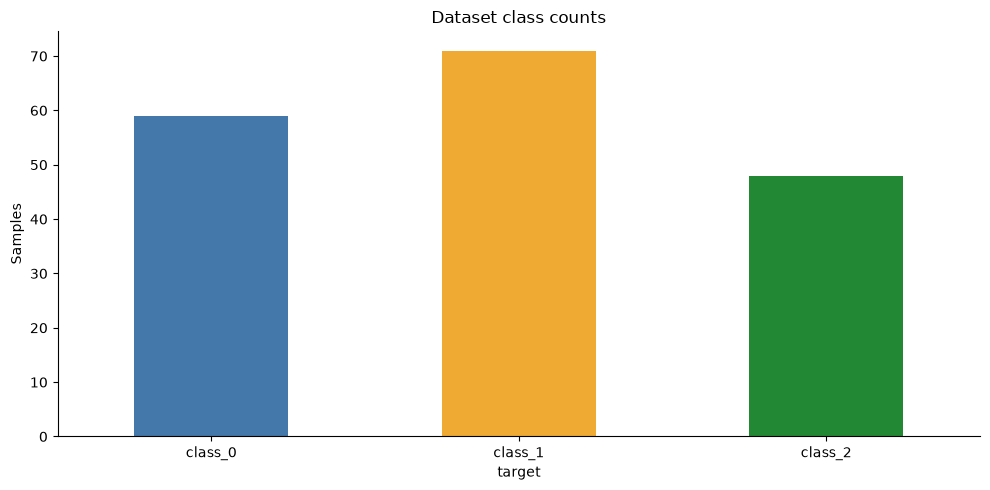

In [26]:
clf_wine = load_wine(as_frame=True)
clf_X = clf_wine.data.copy()
clf_y = clf_wine.target.copy()
clf_class_ids = np.unique(clf_y)
clf_class_names = clf_wine.target_names.tolist()
clf_class_lookup = dict(zip(clf_class_ids, clf_class_names))
clf_df = clf_X.assign(Cultivar=clf_y.map(clf_class_lookup))
print(f'{len(clf_df)} samples | {clf_X.shape[1]} numeric features | {clf_y.nunique()} classes')
display(clf_df.head(8))
display(clf_X.describe().T.round(2))
print('Missing values:', int(clf_df.isna().sum().sum()))
print('Duplicate rows:', int(clf_df.duplicated().sum()))
assert not clf_df.isna().any().any()
assert clf_X.columns.is_unique

clf_y.map(clf_class_lookup).value_counts().sort_index().plot.bar(
    color=['#4477AA', '#EEAA33', '#228833'], rot=0, title='Dataset class counts'
)
plt.ylabel('Samples')
plt.tight_layout()
plt.show()

### 2. Reserve the test set before training

Hold out 25% of observations using a stratified split. Model selection uses only the training set and five stratified cross-validation folds. The test set is used once for the final comparison and diagnostics; we do not adjust hyperparameters after seeing its results.

We optimize **balanced accuracy**, the average recall across the three classes, so each class contributes equally. Ordinary accuracy counts all correctly classified samples equally.

In [27]:
clf_X_train, clf_X_test, clf_y_train, clf_y_test = train_test_split(
    clf_X, clf_y, test_size=0.25, stratify=clf_y, random_state=RANDOM_STATE
)
clf_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print('Training samples:', len(clf_X_train), '| Test samples:', len(clf_X_test))
clf_split_counts = pd.DataFrame({
    'Train': clf_y_train.map(clf_class_lookup).value_counts(),
    'Test': clf_y_test.map(clf_class_lookup).value_counts()
}).sort_index()
display(clf_split_counts)
assert set(clf_X_train.index).isdisjoint(clf_X_test.index)

def clf_show_tree(clf_model, title, max_depth=None):
    plt.figure(figsize=(20, 10))
    plot_tree(clf_model, feature_names=clf_X.columns.tolist(),
              class_names=[clf_class_lookup[clf_c] for clf_c in clf_model.classes_],
              filled=True, rounded=True, precision=3, fontsize=8,
              max_depth=max_depth)
    plt.title(title)
    plt.tight_layout()
    plt.show()

Training samples: 133 | Test samples: 45


,Train,Test
target,,
class_0,44,15
class_1,53,18
class_2,36,12


### 3. Grow the full CART tree

With no depth or leaf-size restrictions, the tree can fit very specific training patterns. Inspect its depth, leaf count, training score, and validation score to see whether training performance carries over to unseen folds.

In the plot, `gini` measures class mixture, `samples` counts training rows at that node, and `value` gives class counts or proportions depending on the installed scikit-learn version. The left branch satisfies the displayed threshold; the right branch does not.

Depth: 4 | Leaves: 8
Training accuracy: 1.0
CV balanced accuracy: 0.904 ± 0.055


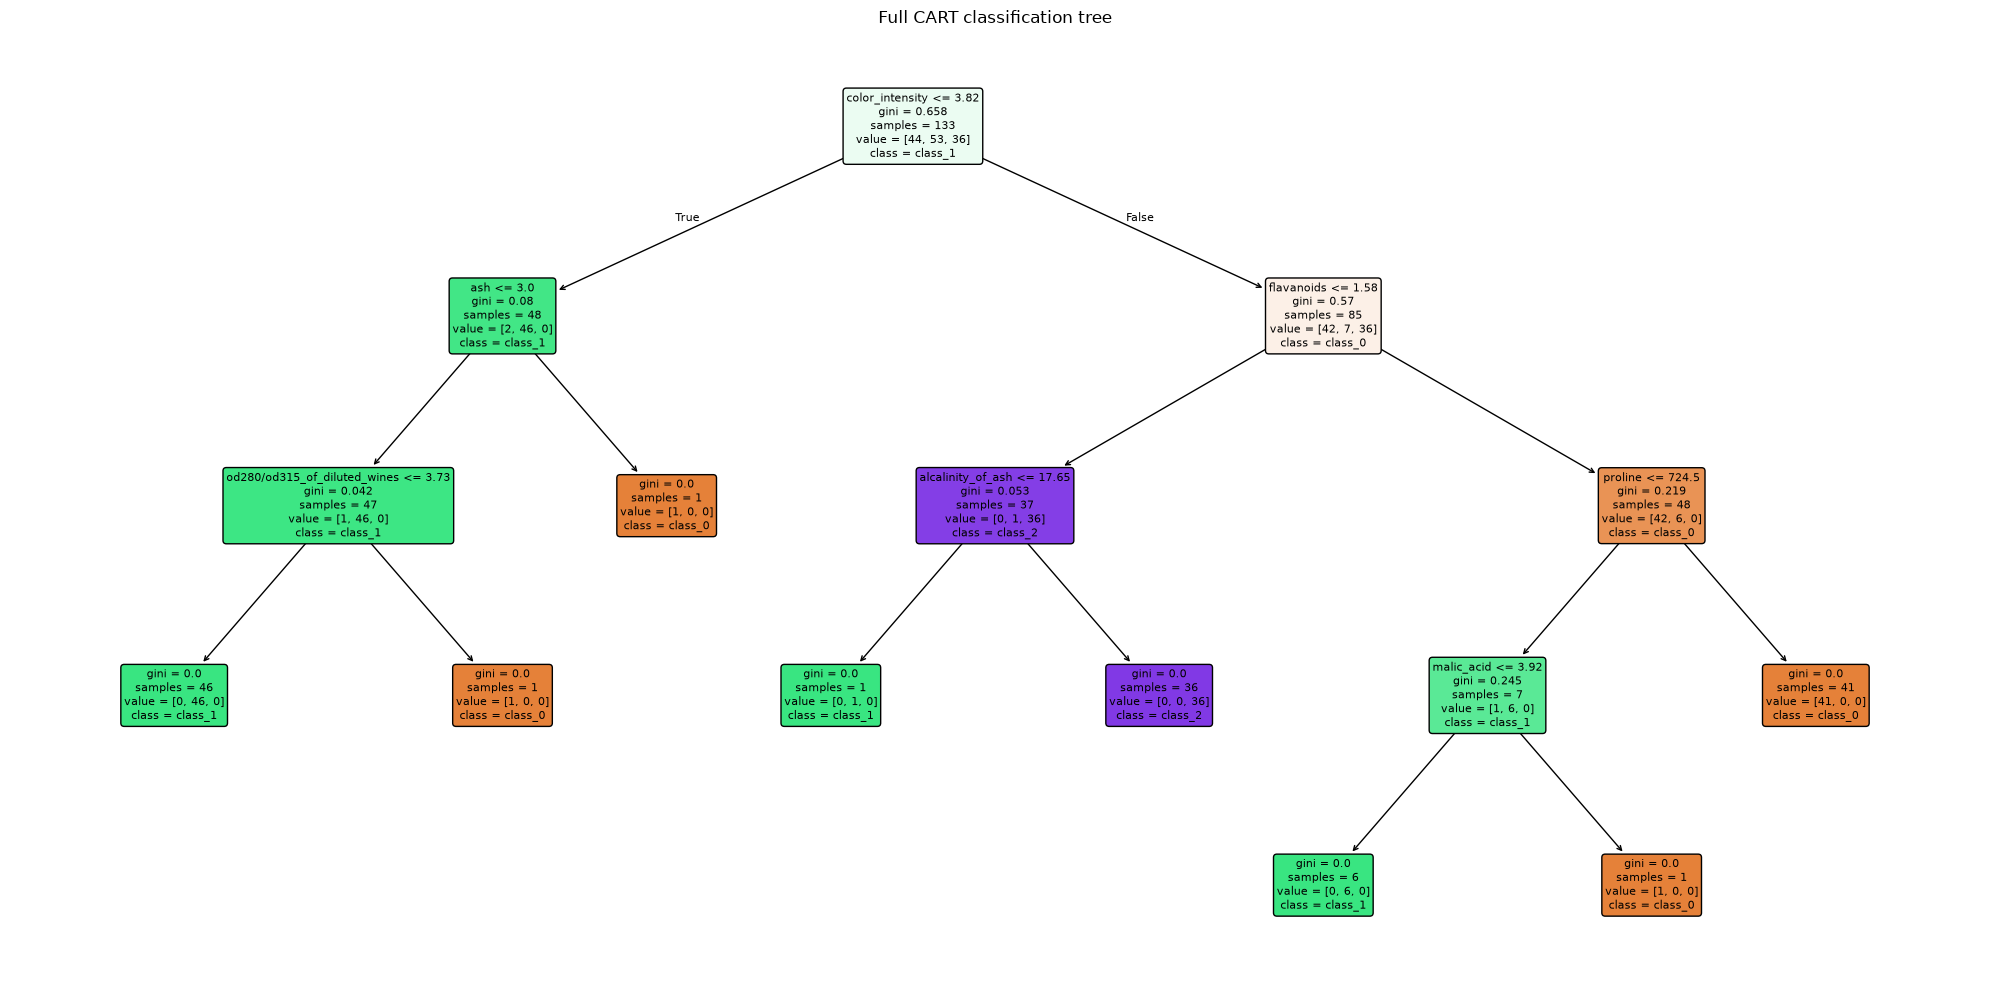

In [28]:
clf_full_tree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_STATE)
clf_full_tree.fit(clf_X_train, clf_y_train)
clf_full_cv_scores = cross_val_score(clf_full_tree, clf_X_train, clf_y_train, cv=clf_cv, scoring='balanced_accuracy')
print('Depth:', clf_full_tree.get_depth(), '| Leaves:', clf_full_tree.get_n_leaves())
print('Training accuracy:', round(clf_full_tree.score(clf_X_train, clf_y_train), 3))
print(f'CV balanced accuracy: {clf_full_cv_scores.mean():.3f} ± {clf_full_cv_scores.std():.3f}')
clf_show_tree(clf_full_tree, 'Full CART classification tree')

### 4. Pre-prune: restrict growth during training

Tune `max_depth` (maximum number of splits along a path) and `min_samples_leaf` (minimum training rows per leaf). Each candidate is evaluated on the same five training folds. Grid search refits the chosen candidate on all training rows.

The reported fold standard deviation describes variation across folds; it is not a confidence interval. The best tuning score can be optimistic because many candidates were compared.

Chosen pre-pruning parameters: {'max_depth': 3, 'min_samples_leaf': 2}
Best CV balanced accuracy: 0.918


,param_max_depth,param_min_samples_leaf,mean_train_score,mean_test_score,std_test_score
9,3,2,0.990,0.918,0.033
21,6,2,0.990,0.912,0.036
13,4,2,0.990,0.912,0.036
17,5,2,0.990,0.912,0.036
10,3,4,0.972,0.912,0.015
22,6,4,0.972,0.912,0.015
18,5,4,0.972,0.912,0.015
14,4,4,0.972,0.912,0.015


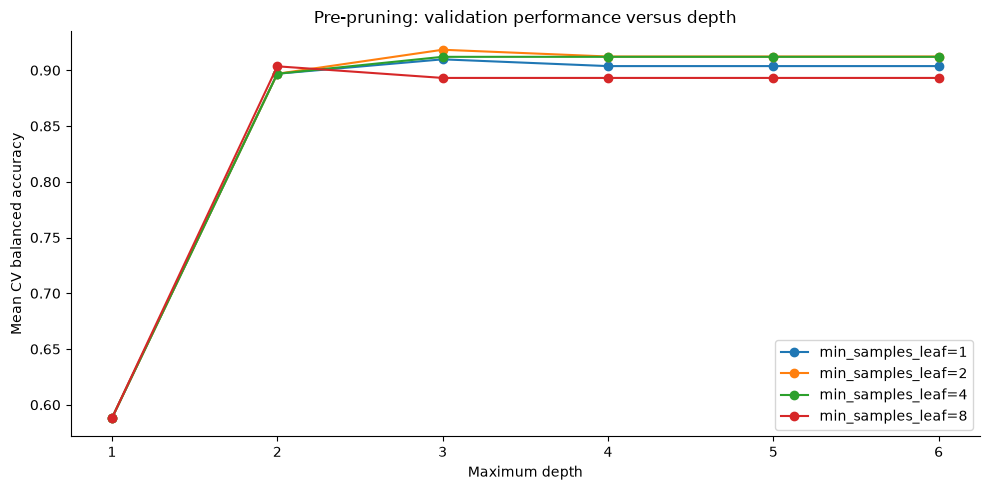

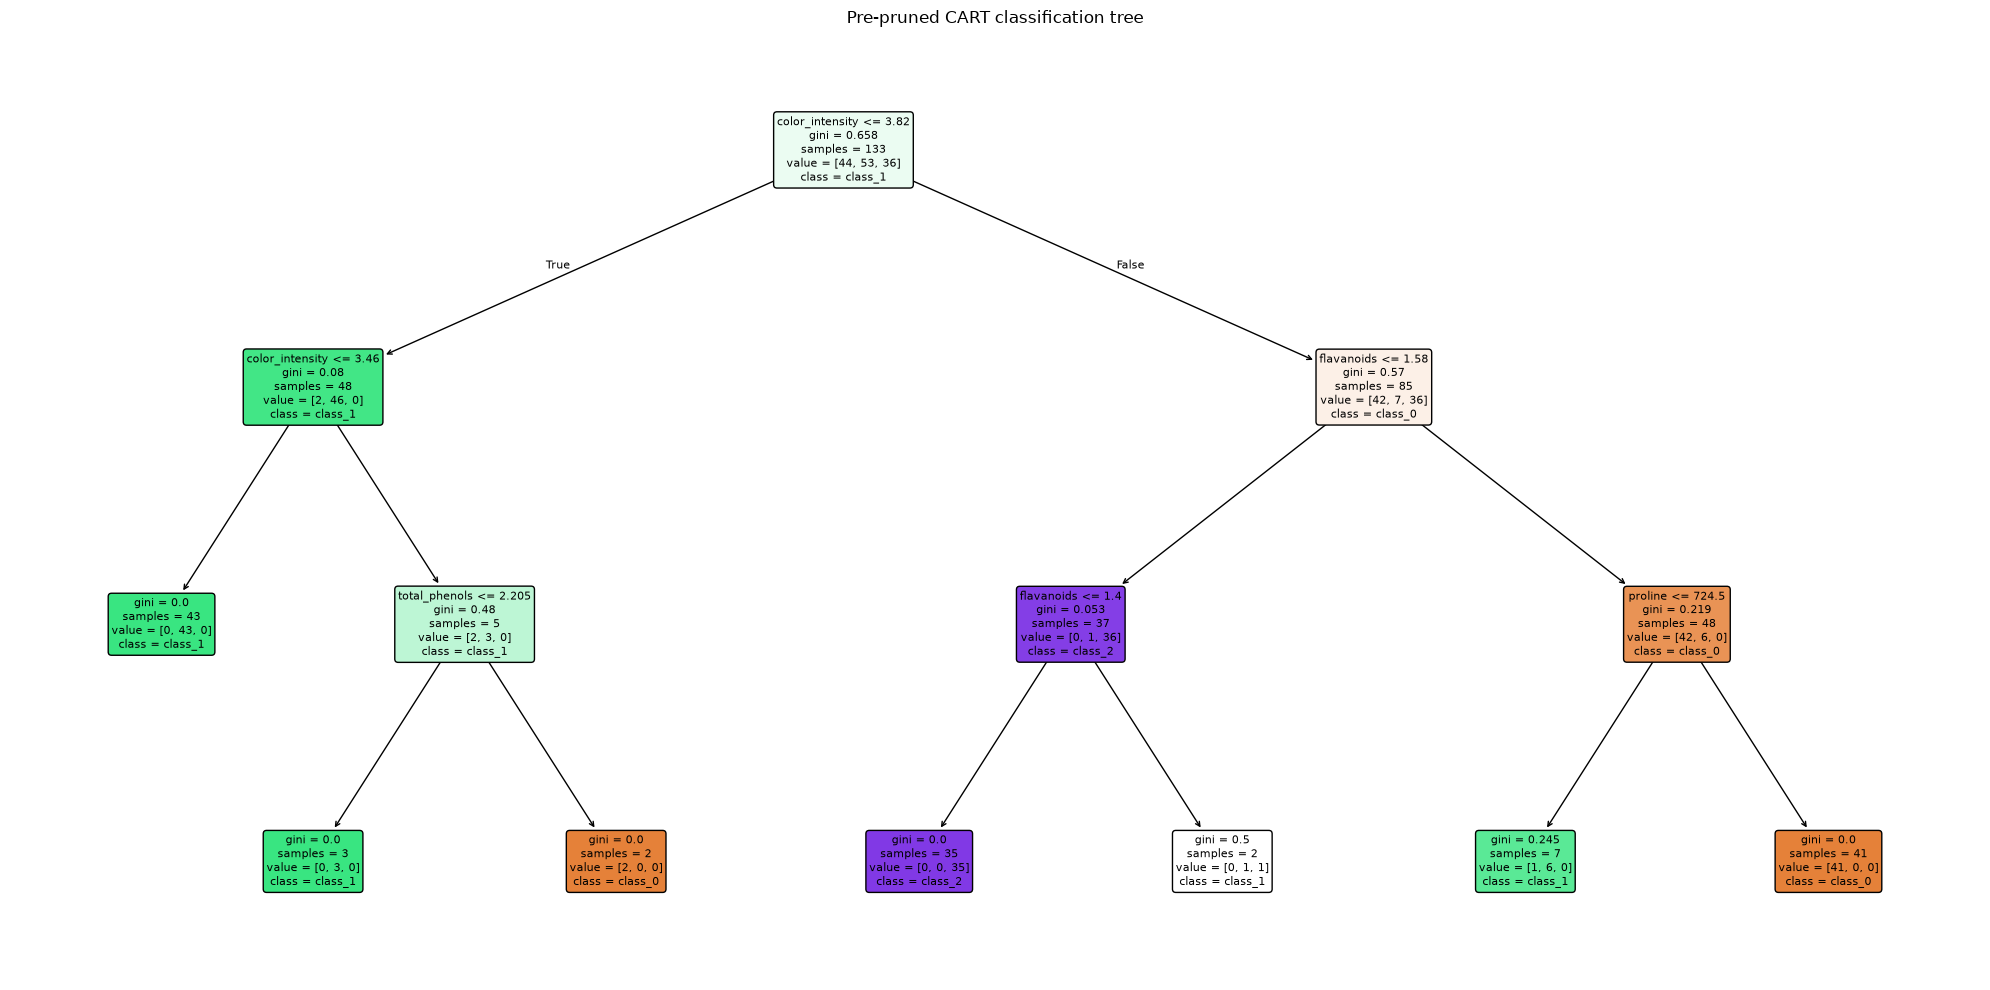

In [29]:
clf_pre_search = GridSearchCV(
    DecisionTreeClassifier(criterion='gini', random_state=RANDOM_STATE),
    param_grid={'max_depth': [1, 2, 3, 4, 5, 6], 'min_samples_leaf': [1, 2, 4, 8]},
    scoring='balanced_accuracy', cv=clf_cv, return_train_score=True, error_score='raise'
)
clf_pre_search.fit(clf_X_train, clf_y_train)
clf_pruned_tree = clf_pre_search.best_estimator_
print('Chosen pre-pruning parameters:', clf_pre_search.best_params_)
print(f'Best CV balanced accuracy: {clf_pre_search.best_score_:.3f}')
clf_pre_results = pd.DataFrame(clf_pre_search.cv_results_)
display(clf_pre_results[['param_max_depth', 'param_min_samples_leaf',
                     'mean_train_score', 'mean_test_score', 'std_test_score']]
        .sort_values('mean_test_score', ascending=False).head(8).round(3))

for clf_leaf_size, clf_group in clf_pre_results.groupby('param_min_samples_leaf'):
    clf_group = clf_group.sort_values('param_max_depth')
    plt.plot(clf_group['param_max_depth'].astype(int), clf_group['mean_test_score'],
             marker='o', label=f'min_samples_leaf={clf_leaf_size}')
plt.xlabel('Maximum depth')
plt.ylabel('Mean CV balanced accuracy')
plt.title('Pre-pruning: validation performance versus depth')
plt.legend()
plt.tight_layout()
plt.show()
clf_show_tree(clf_pruned_tree, 'Pre-pruned CART classification tree')

### 5. Post-prune: cost-complexity pruning

Minimal cost-complexity pruning balances weighted leaf impurity against `ccp_alpha × number of leaves`. Increasing alpha favors smaller trees. Alpha 0 allows the full tree, while a sufficiently large alpha leaves only the root.

The full-training pruning path below illustrates this tradeoff. Hyperparameter selection uses a **fixed alpha grid**, rather than a grid derived from all training labels before cross-validation. Test observations never influence alpha selection.

Chosen alpha: 0.018478497974222907
Best CV balanced accuracy: 0.919
Depth: 3 | Leaves: 4


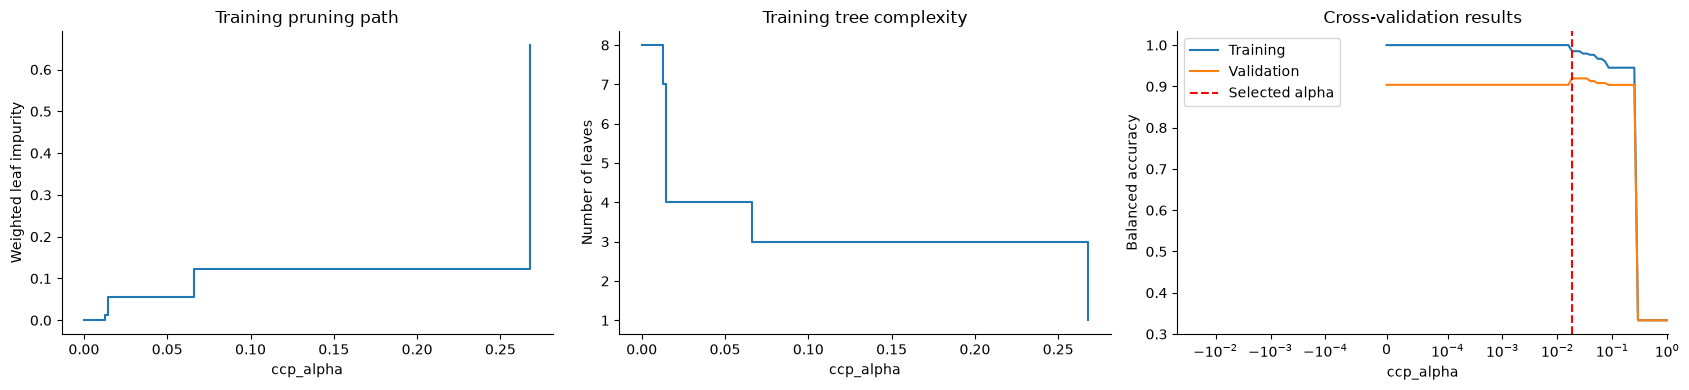

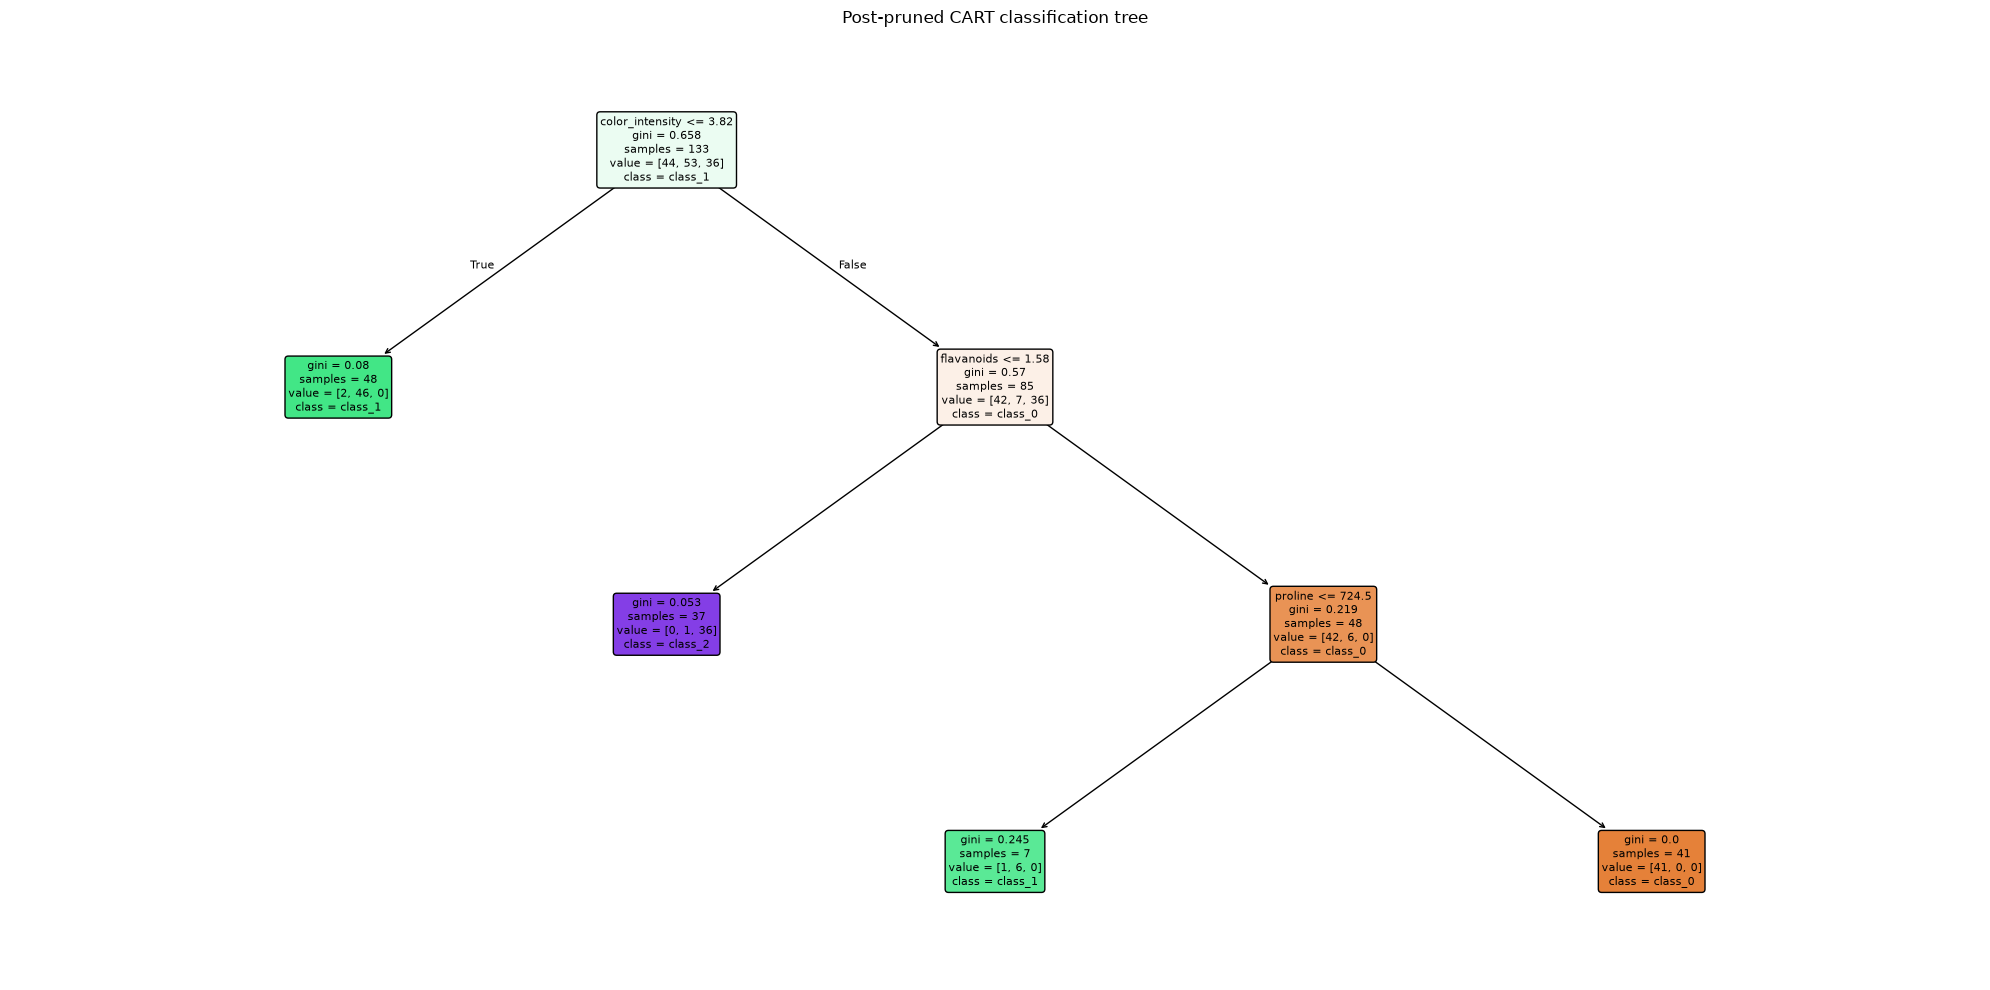

In [30]:
clf_path = clf_full_tree.cost_complexity_pruning_path(clf_X_train, clf_y_train)
clf_alpha_grid = np.r_[0.0, np.logspace(-4, 0, 61)]
clf_post_search = GridSearchCV(
    DecisionTreeClassifier(criterion='gini', random_state=RANDOM_STATE),
    param_grid={'ccp_alpha': clf_alpha_grid}, scoring='balanced_accuracy',
    cv=clf_cv, return_train_score=True, error_score='raise'
)
clf_post_search.fit(clf_X_train, clf_y_train)
clf_post_pruned_tree = clf_post_search.best_estimator_
print('Chosen alpha:', clf_post_search.best_params_['ccp_alpha'])
print(f'Best CV balanced accuracy: {clf_post_search.best_score_:.3f}')
print('Depth:', clf_post_pruned_tree.get_depth(), '| Leaves:', clf_post_pruned_tree.get_n_leaves())

# Full-training fits below illustrate complexity only; they do not select alpha.
clf_path_leaves = [DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=float(clf_a))
               .fit(clf_X_train, clf_y_train).get_n_leaves() for clf_a in clf_path.ccp_alphas]
clf_fig, clf_axes = plt.subplots(1, 3, figsize=(17, 4))
clf_axes[0].step(clf_path.ccp_alphas, clf_path.impurities, where='post')
clf_axes[0].set(xlabel='ccp_alpha', ylabel='Weighted leaf impurity', title='Training pruning path')
clf_axes[1].step(clf_path.ccp_alphas, clf_path_leaves, where='post')
clf_axes[1].set(xlabel='ccp_alpha', ylabel='Number of leaves', title='Training tree complexity')
for clf_score, clf_label in [('mean_train_score', 'Training'), ('mean_test_score', 'Validation')]:
    clf_axes[2].plot(clf_alpha_grid, clf_post_search.cv_results_[clf_score], label=clf_label)
clf_axes[2].axvline(clf_post_search.best_params_['ccp_alpha'], color='red', linestyle='--', label='Selected alpha')
clf_axes[2].set_xscale('symlog', linthresh=0.0001)
clf_axes[2].set(xlabel='ccp_alpha', ylabel='Balanced accuracy', title='Cross-validation results')
clf_axes[2].legend()
plt.tight_layout()
plt.show()
clf_show_tree(clf_post_pruned_tree, 'Post-pruned CART classification tree')

### 6. Select the final model using training data only

Compare the full tree and the best candidates from both pruning searches. Choose the highest mean CV balanced accuracy; exact ties favor fewer leaves, then lower depth. Keeping the full tree eligible avoids assuming that pruning must improve results.

A majority-class baseline helps interpret the scores. Cross-validation results guide selection; the held-out test results in the next section estimate the selected model's performance.

In [31]:
clf_baseline = DummyClassifier(strategy='most_frequent').fit(clf_X_train, clf_y_train)
clf_baseline_cv = cross_val_score(clf_baseline, clf_X_train, clf_y_train, cv=clf_cv, scoring='balanced_accuracy')
clf_models = {'Majority baseline': clf_baseline, 'Full Tree': clf_full_tree,
          'Pre-Pruned Tree': clf_pruned_tree, 'Post-Pruned Tree': clf_post_pruned_tree}
clf_cv_means = {'Majority baseline': clf_baseline_cv.mean(), 'Full Tree': clf_full_cv_scores.mean(),
            'Pre-Pruned Tree': clf_pre_search.best_score_, 'Post-Pruned Tree': clf_post_search.best_score_}
clf_cv_stds = {'Majority baseline': clf_baseline_cv.std(), 'Full Tree': clf_full_cv_scores.std(),
           'Pre-Pruned Tree': clf_pre_search.cv_results_['std_test_score'][clf_pre_search.best_index_],
           'Post-Pruned Tree': clf_post_search.cv_results_['std_test_score'][clf_post_search.best_index_]}
clf_best_model_name = max(
    ['Full Tree', 'Pre-Pruned Tree', 'Post-Pruned Tree'],
    key=lambda clf_name: (clf_cv_means[clf_name], -clf_models[clf_name].get_n_leaves(), -clf_models[clf_name].get_depth())
)
clf_best_model = clf_models[clf_best_model_name]
clf_selection = pd.DataFrame({'CV balanced accuracy': clf_cv_means, 'Fold std': clf_cv_stds})
display(clf_selection.round(3))
print('Selected model:', clf_best_model_name)
print('Selected parameters:', {clf_k: clf_best_model.get_params()[clf_k]
                              for clf_k in ['criterion', 'max_depth', 'min_samples_leaf', 'ccp_alpha']})

,CV balanced accuracy,Fold std
Majority baseline,0.333,0.000
Full Tree,0.904,0.055
Pre-Pruned Tree,0.918,0.033
Post-Pruned Tree,0.919,0.038


Selected model: Post-Pruned Tree
Selected parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'ccp_alpha': np.float64(0.018478497974222907)}


### 7. Evaluate the frozen models on held-out data

**Accuracy:** fraction correct. **Balanced accuracy:** mean per-class recall. **Macro F1:** mean of each class's precision/recall balance. Higher values are better for all three. **Log loss** evaluates predicted probabilities; lower is better and confident wrong predictions are penalized heavily. Tree leaf frequencies can be overconfident, so good classification accuracy does not guarantee good probabilities.

All models are shown for educational comparison. The selected model remains the one chosen above, regardless of test rankings.

,Depth,Leaves,CV balanced accuracy,Train balanced accuracy,Test accuracy,Test balanced accuracy,Test macro F1,Test log loss
Model,,,,,,,,
Majority baseline,NaN,NaN,0.333,0.333,0.400,0.333,0.190,21.626
Full Tree,4.0,8.0,0.904,1.000,0.956,0.950,0.956,1.602
Pre-Pruned Tree,3.0,7.0,0.918,0.983,1.000,1.000,1.000,0.014
Post-Pruned Tree,3.0,4.0,0.919,0.971,0.956,0.956,0.959,0.175


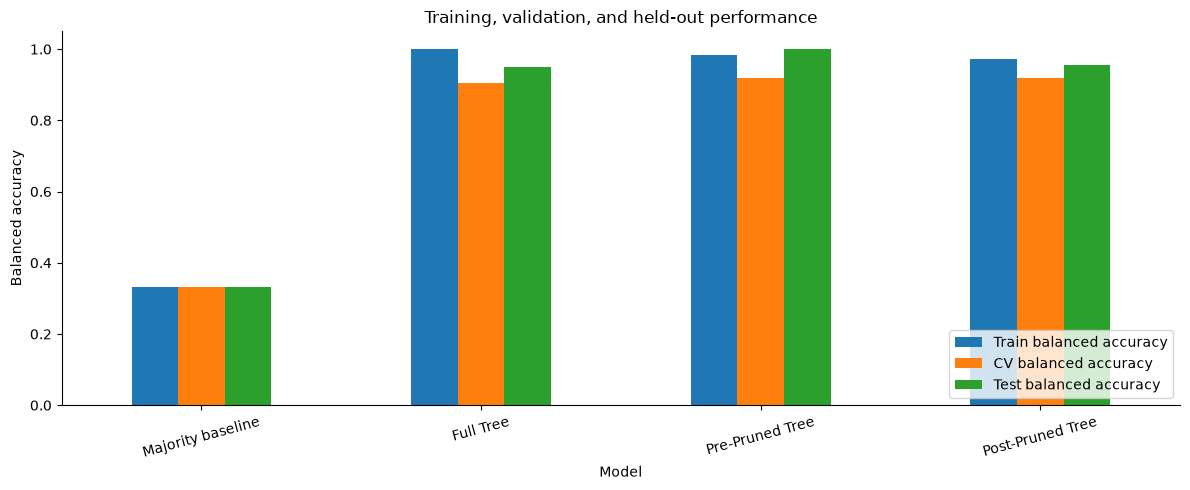

In [32]:
clf_rows = []
for clf_name, clf_model in clf_models.items():
    clf_train_pred = clf_model.predict(clf_X_train)
    clf_test_pred = clf_model.predict(clf_X_test)
    clf_rows.append({
        'Model': clf_name,
        'Depth': clf_model.get_depth() if isinstance(clf_model, DecisionTreeClassifier) else np.nan,
        'Leaves': clf_model.get_n_leaves() if isinstance(clf_model, DecisionTreeClassifier) else np.nan,
        'CV balanced accuracy': clf_cv_means[clf_name],
        'Train balanced accuracy': balanced_accuracy_score(clf_y_train, clf_train_pred),
        'Test accuracy': accuracy_score(clf_y_test, clf_test_pred),
        'Test balanced accuracy': balanced_accuracy_score(clf_y_test, clf_test_pred),
        'Test macro F1': f1_score(clf_y_test, clf_test_pred, average='macro', zero_division=0),
        'Test log loss': log_loss(clf_y_test, clf_model.predict_proba(clf_X_test), labels=clf_model.classes_)
    })
clf_comparison = pd.DataFrame(clf_rows).set_index('Model')
display(clf_comparison.round(3))
clf_comparison[['Train balanced accuracy', 'CV balanced accuracy', 'Test balanced accuracy']].plot.bar(
    figsize=(12, 5), rot=15, ylim=(0, 1.05), title='Training, validation, and held-out performance'
)
plt.ylabel('Balanced accuracy')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Classification report: Post-Pruned Tree
              precision    recall  f1-score   support

     class_0       1.00      0.87      0.93        15
     class_1       0.90      1.00      0.95        18
     class_2       1.00      1.00      1.00        12

    accuracy                           0.96        45
   macro avg       0.97      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



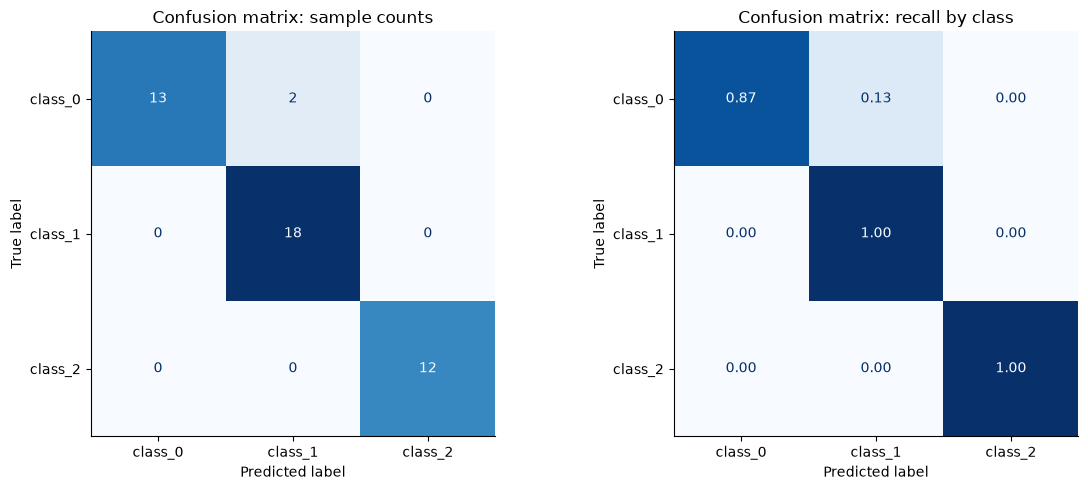

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Actual,Predicted,Largest leaf probability,Correct
35,13.48,1.81,2.41,20.5,100.0,2.70,2.98,0.26,1.86,5.10,1.04,3.47,920.0,class_0,class_0,1.000,True
93,12.29,2.83,2.22,18.0,88.0,2.45,2.25,0.25,1.99,2.15,1.15,3.30,290.0,class_1,class_1,0.958,True
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,class_0,class_0,1.000,True
28,13.87,1.90,2.80,19.4,107.0,2.95,2.97,0.37,1.76,4.50,1.25,3.40,915.0,class_0,class_0,1.000,True
87,11.65,1.67,2.62,26.0,88.0,1.92,1.61,0.40,1.34,2.60,1.36,3.21,562.0,class_1,class_1,0.958,True
42,13.88,1.89,2.59,15.0,101.0,3.25,3.56,0.17,1.70,5.43,0.88,3.56,1095.0,class_0,class_0,1.000,True
18,14.19,1.59,2.48,16.5,108.0,3.30,3.93,0.32,1.86,8.70,1.23,2.82,1680.0,class_0,class_0,1.000,True
60,12.33,1.10,2.28,16.0,101.0,2.05,1.09,0.63,0.41,3.27,1.25,1.67,680.0,class_1,class_1,0.958,True
98,12.37,1.07,2.10,18.5,88.0,3.52,3.75,0.24,1.95,4.50,1.04,2.77,660.0,class_1,class_1,0.857,True
130,12.86,1.35,2.32,18.0,122.0,1.51,1.25,0.21,0.94,4.10,0.76,1.29,630.0,class_2,class_2,0.973,True


Misclassified test examples: 2


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Actual,Predicted,Largest leaf probability,Correct
22,13.71,1.86,2.36,16.6,101.0,2.61,2.88,0.27,1.69,3.8,1.11,4.00,1035.0,class_0,class_1,0.958,False
38,13.07,1.50,2.10,15.5,98.0,2.40,2.64,0.28,1.37,3.7,1.18,2.69,1020.0,class_0,class_1,0.958,False


In [33]:
clf_predictions = clf_best_model.predict(clf_X_test)
clf_probabilities = clf_best_model.predict_proba(clf_X_test)
print(f'Classification report: {clf_best_model_name}')
print(classification_report(clf_y_test, clf_predictions, labels=clf_class_ids,
                            target_names=clf_class_names, zero_division=0))
clf_fig, clf_axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(clf_y_test, clf_predictions, labels=clf_class_ids,
    display_labels=clf_class_names, cmap='Blues', ax=clf_axes[0], colorbar=False)
clf_axes[0].set_title('Confusion matrix: sample counts')
ConfusionMatrixDisplay.from_predictions(clf_y_test, clf_predictions, labels=clf_class_ids,
    display_labels=clf_class_names, normalize='true', values_format='.2f',
    cmap='Blues', ax=clf_axes[1], colorbar=False)
clf_axes[1].set_title('Confusion matrix: recall by class')
plt.tight_layout()
plt.show()

clf_results = clf_X_test.copy()
clf_results['Actual'] = clf_y_test.map(clf_class_lookup)
clf_results['Predicted'] = pd.Series(clf_predictions, index=clf_X_test.index).map(clf_class_lookup)
clf_results['Largest leaf probability'] = clf_probabilities.max(axis=1)
clf_results['Correct'] = clf_predictions == clf_y_test.to_numpy()
display(clf_results.head(10).round(3))
print('Misclassified test examples:', int((~clf_results['Correct']).sum()))
display(clf_results.loc[~clf_results['Correct']].round(3))

### 8. Interpret the selected tree

The root split below demonstrates the CART calculation: parent Gini minus the child impurities weighted by their sample counts. It measures local impurity reduction, not predictive accuracy.

Impurity importance sums reductions throughout the fitted tree and can favor features with many possible thresholds. Permutation importance measures the drop in held-out balanced accuracy when one feature is shuffled. Correlated features can share or mask importance. These diagnostics are interpreted after model selection and are not used to retune it. Error bars show variation over repeated shuffles, not confidence intervals.

Root split: color_intensity <= 3.820
Parent Gini: 0.6585
Weighted child Gini: 0.3929
Gini decrease: 0.2656


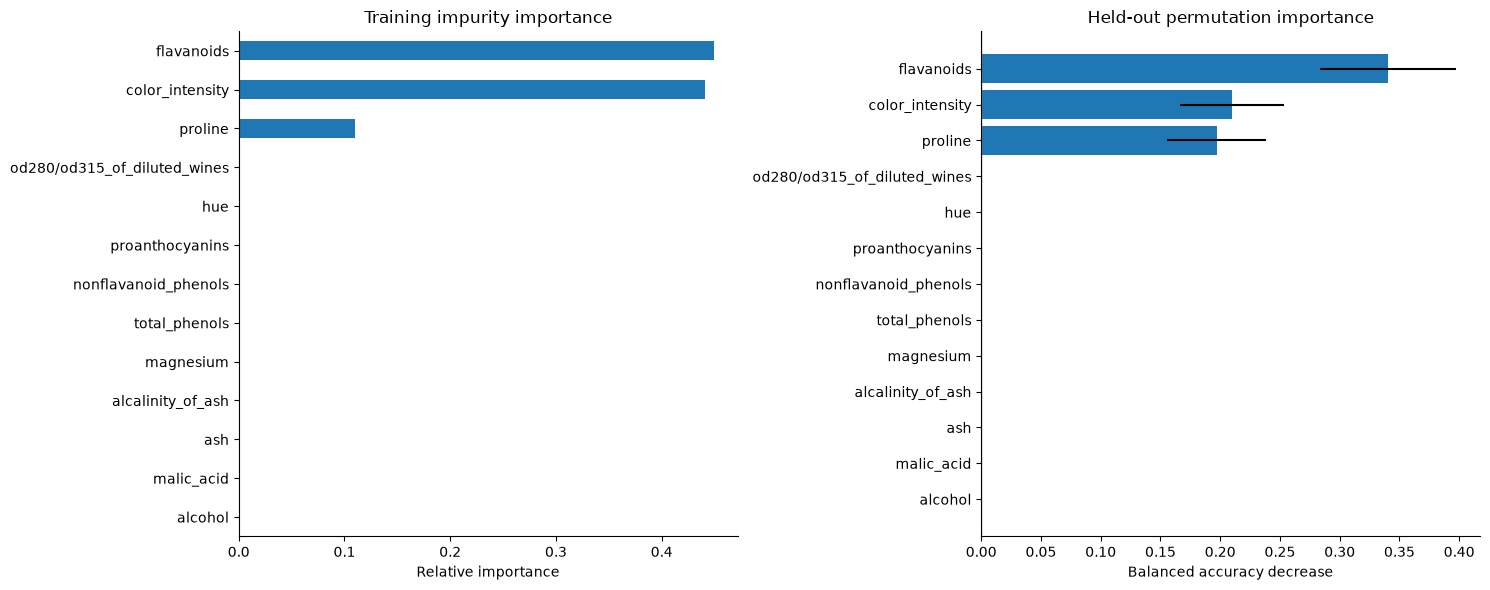

Selected tree rules:
|--- color_intensity <= 3.820
|   |--- class: 1
|--- color_intensity >  3.820
|   |--- flavanoids <= 1.580
|   |   |--- class: 2
|   |--- flavanoids >  1.580
|   |   |--- proline <= 724.500
|   |   |   |--- class: 1
|   |   |--- proline >  724.500
|   |   |   |--- class: 0



In [34]:
clf_structure = clf_best_model.tree_
if clf_structure.children_left[0] != -1:
    clf_left, clf_right = clf_structure.children_left[0], clf_structure.children_right[0]
    clf_counts = clf_structure.weighted_n_node_samples
    clf_weighted_children = (clf_counts[clf_left] * clf_structure.impurity[clf_left] +
                         clf_counts[clf_right] * clf_structure.impurity[clf_right]) / clf_counts[0]
    print(f'Root split: {clf_X.columns[clf_structure.feature[0]]} <= {clf_structure.threshold[0]:.3f}')
    print(f'Parent Gini: {clf_structure.impurity[0]:.4f}')
    print(f'Weighted child Gini: {clf_weighted_children:.4f}')
    print(f'Gini decrease: {clf_structure.impurity[0] - clf_weighted_children:.4f}')
else:
    print('The selected tree is a single leaf; there is no root split.')

clf_impurity = pd.Series(clf_best_model.feature_importances_, index=clf_X.columns).sort_values()
clf_permutation = permutation_importance(clf_best_model, clf_X_test, clf_y_test,
    scoring='balanced_accuracy', n_repeats=30, random_state=RANDOM_STATE)
clf_perm_table = pd.DataFrame({'Mean score decrease': clf_permutation.importances_mean,
                           'Shuffle std': clf_permutation.importances_std}, index=clf_X.columns)
clf_perm_table = clf_perm_table.sort_values('Mean score decrease')
clf_fig, clf_axes = plt.subplots(1, 2, figsize=(15, 6))
clf_impurity.plot.barh(ax=clf_axes[0], title='Training impurity importance')
clf_axes[0].set_xlabel('Relative importance')
clf_axes[1].barh(clf_perm_table.index, clf_perm_table['Mean score decrease'], xerr=clf_perm_table['Shuffle std'])
clf_axes[1].axvline(0, color='gray', linewidth=1)
clf_axes[1].set(title='Held-out permutation importance', xlabel='Balanced accuracy decrease')
plt.tight_layout()
plt.show()
print('Selected tree rules:')
print(export_text(clf_best_model, feature_names=clf_X.columns.tolist(), decimals=3))

### 9. Predict a hypothetical new sample

Create a complete feature row using **training medians**, then supply two example measurements. This is an illustrative synthetic sample with no known true class, not an additional test observation. In practice, replace all fields with measurements collected in the same units as the training data.

The probability vector is the class distribution in the reached leaf. It should not be interpreted as calibrated confidence.

In [35]:
clf_new_sample = clf_X_train.median().to_frame().T
clf_new_sample.index = ['Hypothetical sample']
clf_new_sample.loc[:, 'alcohol'] = 13.2
clf_new_sample.loc[:, 'proline'] = 850.0
clf_new_sample = clf_new_sample[clf_X.columns]
display(clf_new_sample.round(3))
clf_new_prediction = clf_best_model.predict(clf_new_sample)[0]
print('Predicted cultivar:', clf_class_lookup[clf_new_prediction])
display(pd.DataFrame(clf_best_model.predict_proba(clf_new_sample),
                     columns=[clf_class_lookup[clf_c] for clf_c in clf_best_model.classes_], index=clf_new_sample.index))
clf_leaf_id = clf_best_model.apply(clf_new_sample)[0]
print('Reached leaf:', clf_leaf_id)
print('Training samples in this leaf:', clf_best_model.tree_.n_node_samples[clf_leaf_id])

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
Hypothetical sample,13.2,1.81,2.36,20.0,98.0,2.4,2.14,0.34,1.57,4.68,0.96,2.78,850.0


Predicted cultivar: class_0


,class_0,class_1,class_2
Hypothetical sample,1.0,0.0,0.0


Reached leaf: 6
Training samples in this leaf: 41


### 10. Conclusions from this run

The following summary is generated from the actual results, so it stays consistent when the notebook is rerun.

In [36]:
clf_selected_results = clf_comparison.loc[clf_best_model_name]
print(f'Selected by training CV: {clf_best_model_name}')
print(f'Tree complexity: depth {clf_best_model.get_depth()}, {clf_best_model.get_n_leaves()} leaves')
print(f'CV balanced accuracy: {clf_cv_means[clf_best_model_name]:.1%}')
print(f'Test accuracy: {clf_selected_results["Test accuracy"]:.1%}')
print(f'Test balanced accuracy: {clf_selected_results["Test balanced accuracy"]:.1%}')
print(f'Test macro F1: {clf_selected_results["Test macro F1"]:.3f}')
print(f'Test mistakes: {(clf_predictions != clf_y_test.to_numpy()).sum()} / {len(clf_y_test)}')
print(f'One test prediction changes ordinary accuracy by {100 / len(clf_y_test):.2f} percentage points.')

# Basic consistency checks for the saved workflow.
assert len(clf_predictions) == len(clf_y_test)
assert np.allclose(clf_probabilities.sum(axis=1), 1)
assert set(clf_predictions).issubset(set(clf_class_ids))
assert set(clf_best_model.feature_names_in_) == set(clf_X.columns)
print('Workflow checks passed.')

Selected by training CV: Post-Pruned Tree
Tree complexity: depth 3, 4 leaves
CV balanced accuracy: 91.9%
Test accuracy: 95.6%
Test balanced accuracy: 95.6%
Test macro F1: 0.959
Test mistakes: 2 / 45
One test prediction changes ordinary accuracy by 2.22 percentage points.
Workflow checks passed.


#### Key takeaways

- CART uses binary threshold splits for this multiclass problem; it does not require one tree per class.
- Full trees can overfit. Pre-pruning constrains growth, while cost-complexity post-pruning removes complexity. Either can help, but improvement is not guaranteed.
- Splitting before training and keeping hyperparameter selection within training cross-validation prevents test feedback from driving the model choice.
- This dataset is still small. A single held-out split is an estimate, not a guarantee of performance on wines from other sources. Nested cross-validation or additional external data would support stronger claims.
- Feature importance is model-specific and does not establish causation. Leaf class frequencies are not automatically calibrated probabilities.
- This classification workflow parallels the regression notebook: replace numeric-price predictions and MAE/RMSE with class predictions and classification metrics.

<a id="regression"></a>
## Part 2: CART Regression: House Price Prediction

**Objective:** predict a continuous house price from property characteristics using CART (Classification and Regression Trees). Compare an unrestricted tree with pre-pruned and cost-complexity post-pruned trees, selecting the final model using training-only cross-validation.

**Workflow:** generate and inspect data → reserve a test set → train and tune trees → select by cross-validation → evaluate held-out predictions → interpret the model → predict a new house.

CART uses binary threshold splits. With the squared-error criterion, each leaf predicts the **mean training target** in that leaf. Unlike classification, which predicts class labels and reduces class impurity, this regression tree reduces squared prediction error.

We generate 400 synthetic house prices in **lakhs of rupees** with a fixed random seed. These are educational data, not actual property transactions; results measure recovery of the simulated relationships and do not establish real-world valuation accuracy. All features are numeric, so categorical encoding and feature scaling are unnecessary.

### 1. Generate and inspect the regression dataset

The simulation gives larger houses and additional bedrooms higher prices, while age and distance reduce prices. Houses within 5 km receive an additional premium. Gaussian noise represents unexplained variation. Prices are clipped at 10 lakhs and rounded to two decimals.

| Variable | Meaning | Unit |
|---|---|---|
| Area_sqft | Floor area | square feet |
| Bedrooms | Number of bedrooms | count |
| Age_years | Property age | years |
| Distance_km | Distance from the assumed city center | km |
| Price_lakhs | Prediction target | lakhs of rupees |

These features are generated independently for simplicity. Real housing data can have correlations, location effects, missing values, and changing market conditions that this exercise does not model.

In [37]:
reg_rng = np.random.default_rng(RANDOM_STATE)
reg_n = 400

reg_df = pd.DataFrame({
    'Area_sqft': reg_rng.integers(600, 3501, reg_n),
    'Bedrooms': reg_rng.integers(1, 6, reg_n),
    'Age_years': reg_rng.integers(0, 31, reg_n),
    'Distance_km': reg_rng.uniform(1, 25, reg_n).round(1),
})
reg_df['Price_lakhs'] = (
    15 + 0.035 * reg_df['Area_sqft'] + 4 * reg_df['Bedrooms']
    - 0.6 * reg_df['Age_years'] - 1.2 * reg_df['Distance_km']
    + 15 * (reg_df['Distance_km'] <= 5)
    + reg_rng.normal(0, 5, reg_n)
).clip(lower=10).round(2)

print('Dataset shape:', reg_df.shape)
display(reg_df.head(10))
display(reg_df.describe().round(2))
assert not reg_df.isna().any().any()

Dataset shape: (400, 5)


,Area_sqft,Bedrooms,Age_years,Distance_km,Price_lakhs
0,858,5,0,12.5,46.32
1,2845,4,9,19.3,106.64
2,2498,2,15,22.7,74.36
3,1873,5,28,18.3,60.38
4,1856,3,22,24.1,49.31
5,3090,3,24,19.8,98.11
6,849,3,16,21.8,24.04
7,2623,1,3,3.7,114.57
8,1184,5,12,18.6,41.71
9,873,1,30,11.6,23.16


,Area_sqft,Bedrooms,Age_years,Distance_km,Price_lakhs
count,400.00,400.00,400.00,400.00,400.00
mean,2040.36,3.07,14.96,12.98,76.89
std,818.89,1.44,8.95,7.16,32.64
min,615.00,1.00,0.00,1.00,10.00
25%,1363.25,2.00,7.00,6.80,51.54
50%,2017.00,3.00,15.00,12.80,76.73
75%,2761.50,4.00,23.00,19.42,100.28
max,3489.00,5.00,30.00,25.00,152.84


### 2. Separate features and target, then split the data

Reserve 25% (100 rows) for testing and use the remaining 300 rows for training and model selection. A fixed random seed makes the experiment reproducible. No test observations are used to fit or tune a model.

Five shuffled cross-validation folds estimate validation error within the training set. All candidates use the same folds. We optimize mean fold **MSE** and report its square root as **CV RMSE**; this is the square root of mean fold MSE, not the arithmetic mean of fold RMSEs.

In [38]:
reg_X = reg_df.drop(columns='Price_lakhs')
reg_y = reg_df['Price_lakhs']
reg_X_train, reg_X_test, reg_y_train, reg_y_test = train_test_split(
    reg_X, reg_y, test_size=0.25, random_state=RANDOM_STATE
)
print('Training rows:', len(reg_X_train))
print('Testing rows:', len(reg_X_test))
print('Features:', reg_X.columns.tolist())
reg_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
assert set(reg_X_train.index).isdisjoint(reg_X_test.index)
assert list(reg_X_train.columns) == list(reg_X_test.columns)

Training rows: 300
Testing rows: 100
Features: ['Area_sqft', 'Bedrooms', 'Age_years', 'Distance_km']


### 3. Train the full CART regression tree

For a node containing $n$ observations, squared-error impurity is $\frac{1}{n}\sum_i(y_i-\bar{y})^2$. CART chooses a feature and threshold that reduce the sample-weighted child impurity. Predictions are constant within each leaf.

An unrestricted tree can create one leaf per training observation, giving zero training error. Its cross-validation error is a better indication of generalization than its training score. In tree diagrams, `value` is the predicted mean price, `samples` is the training count, and `squared_error` is the node's target variance.

In [39]:
reg_full_tree = DecisionTreeRegressor(criterion='squared_error', random_state=RANDOM_STATE)
reg_full_tree.fit(reg_X_train, reg_y_train)
print('Tree depth:', reg_full_tree.get_depth())
print('Number of leaves:', reg_full_tree.get_n_leaves())
print('Training R²:', round(reg_full_tree.score(reg_X_train, reg_y_train), 3))
reg_full_cv_mse = -cross_val_score(reg_full_tree, reg_X_train, reg_y_train, scoring='neg_mean_squared_error', cv=reg_cv)
print('Full-tree CV RMSE:', round(np.sqrt(reg_full_cv_mse.mean()), 2), 'lakhs')

Tree depth: 14
Number of leaves: 300
Training R²: 1.0
Full-tree CV RMSE: 11.46 lakhs


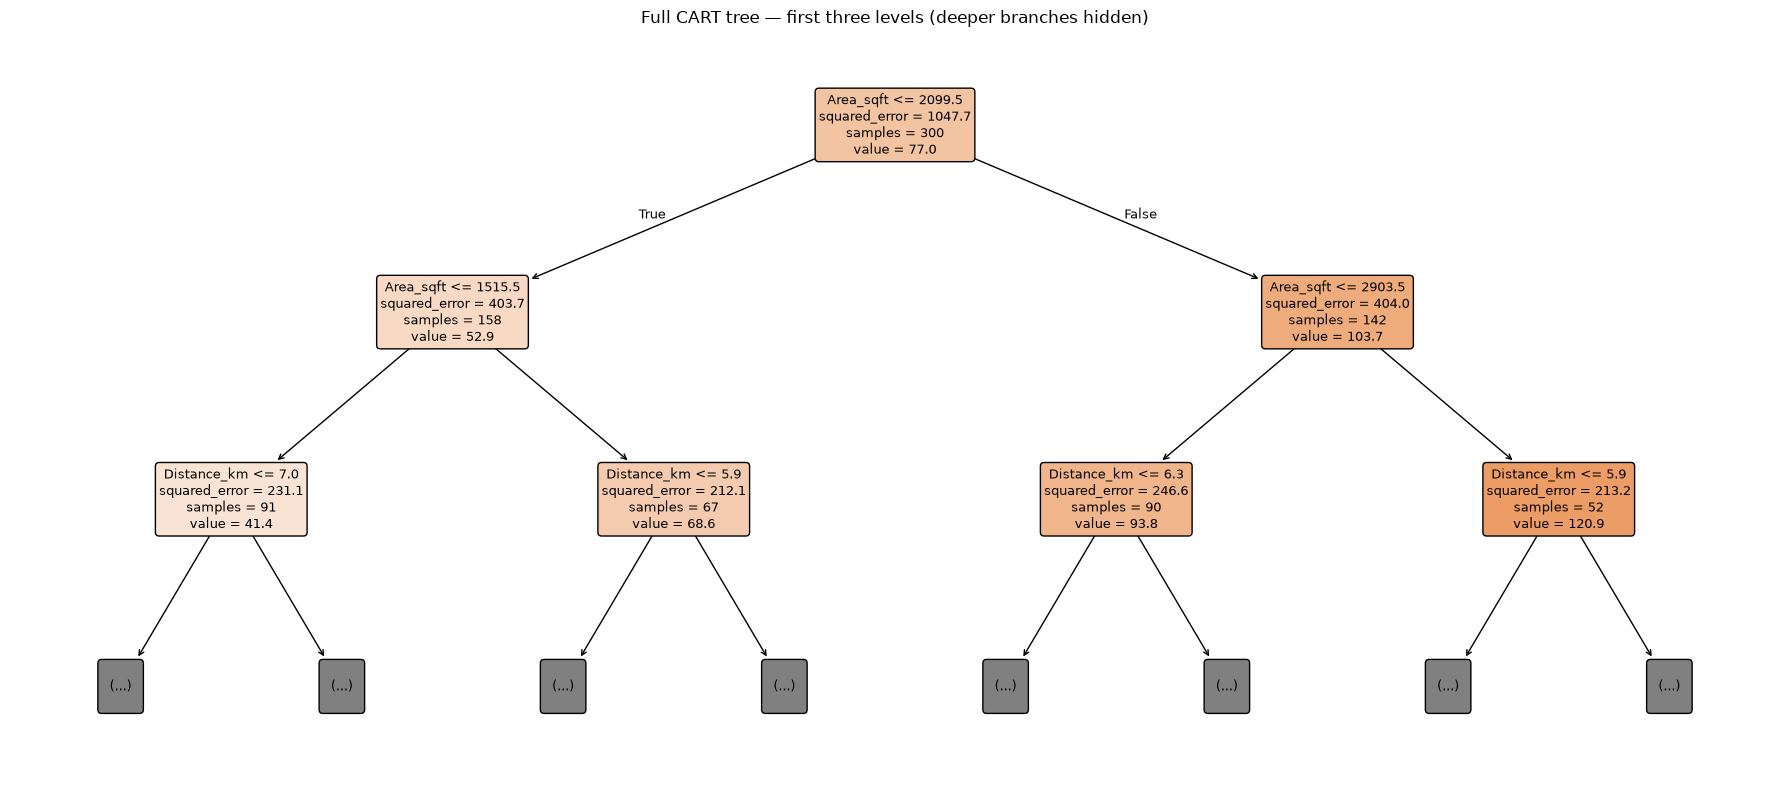

In [40]:
plt.figure(figsize=(18, 8))
plot_tree(reg_full_tree, feature_names=reg_X.columns.tolist(), filled=True,
          rounded=True, max_depth=2, precision=1, fontsize=9)
plt.title('Full CART tree — first three levels (deeper branches hidden)')
plt.tight_layout()
plt.show()

### 4. Pre-pruning: restrict tree growth

Tune maximum depth and minimum samples per leaf using five-fold training-only cross-validation. A shallow tree may underfit; very small leaves can fit noise. The grid includes unrestricted depth so validation can determine whether a depth limit helps when a minimum leaf size is enforced.

Grid search refits the chosen candidate on all training rows. Scores used for tuning can be optimistic because multiple candidates were compared; the held-out test set provides a separate evaluation.

In [41]:
reg_pre_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid={'max_depth': [2, 3, 4, 5, 6, 8, 10, None], 'min_samples_leaf': [2, 5, 10]},
    scoring='neg_mean_squared_error', cv=reg_cv, error_score='raise'
)
reg_pre_search.fit(reg_X_train, reg_y_train)
reg_pruned_tree = reg_pre_search.best_estimator_
print('Best pre-pruning parameters:', reg_pre_search.best_params_)
print('Cross-validation RMSE:', round(np.sqrt(-reg_pre_search.best_score_), 2))
print('Depth:', reg_pruned_tree.get_depth(), '| Leaves:', reg_pruned_tree.get_n_leaves())
reg_pre_results = pd.DataFrame(reg_pre_search.cv_results_)
reg_pre_results['CV RMSE'] = np.sqrt(-reg_pre_results['mean_test_score'])
display(reg_pre_results[['param_max_depth', 'param_min_samples_leaf', 'CV RMSE']]
        .sort_values('CV RMSE').head(8).round(3))

Best pre-pruning parameters: {'max_depth': 10, 'min_samples_leaf': 5}
Cross-validation RMSE: 10.82
Depth: 9 | Leaves: 48


,param_max_depth,param_min_samples_leaf,CV RMSE
19,10,5,10.819
22,None,5,10.819
16,8,5,10.822
13,6,5,10.945
18,10,2,11.136
21,None,2,11.198
15,8,2,11.330
10,5,5,11.372


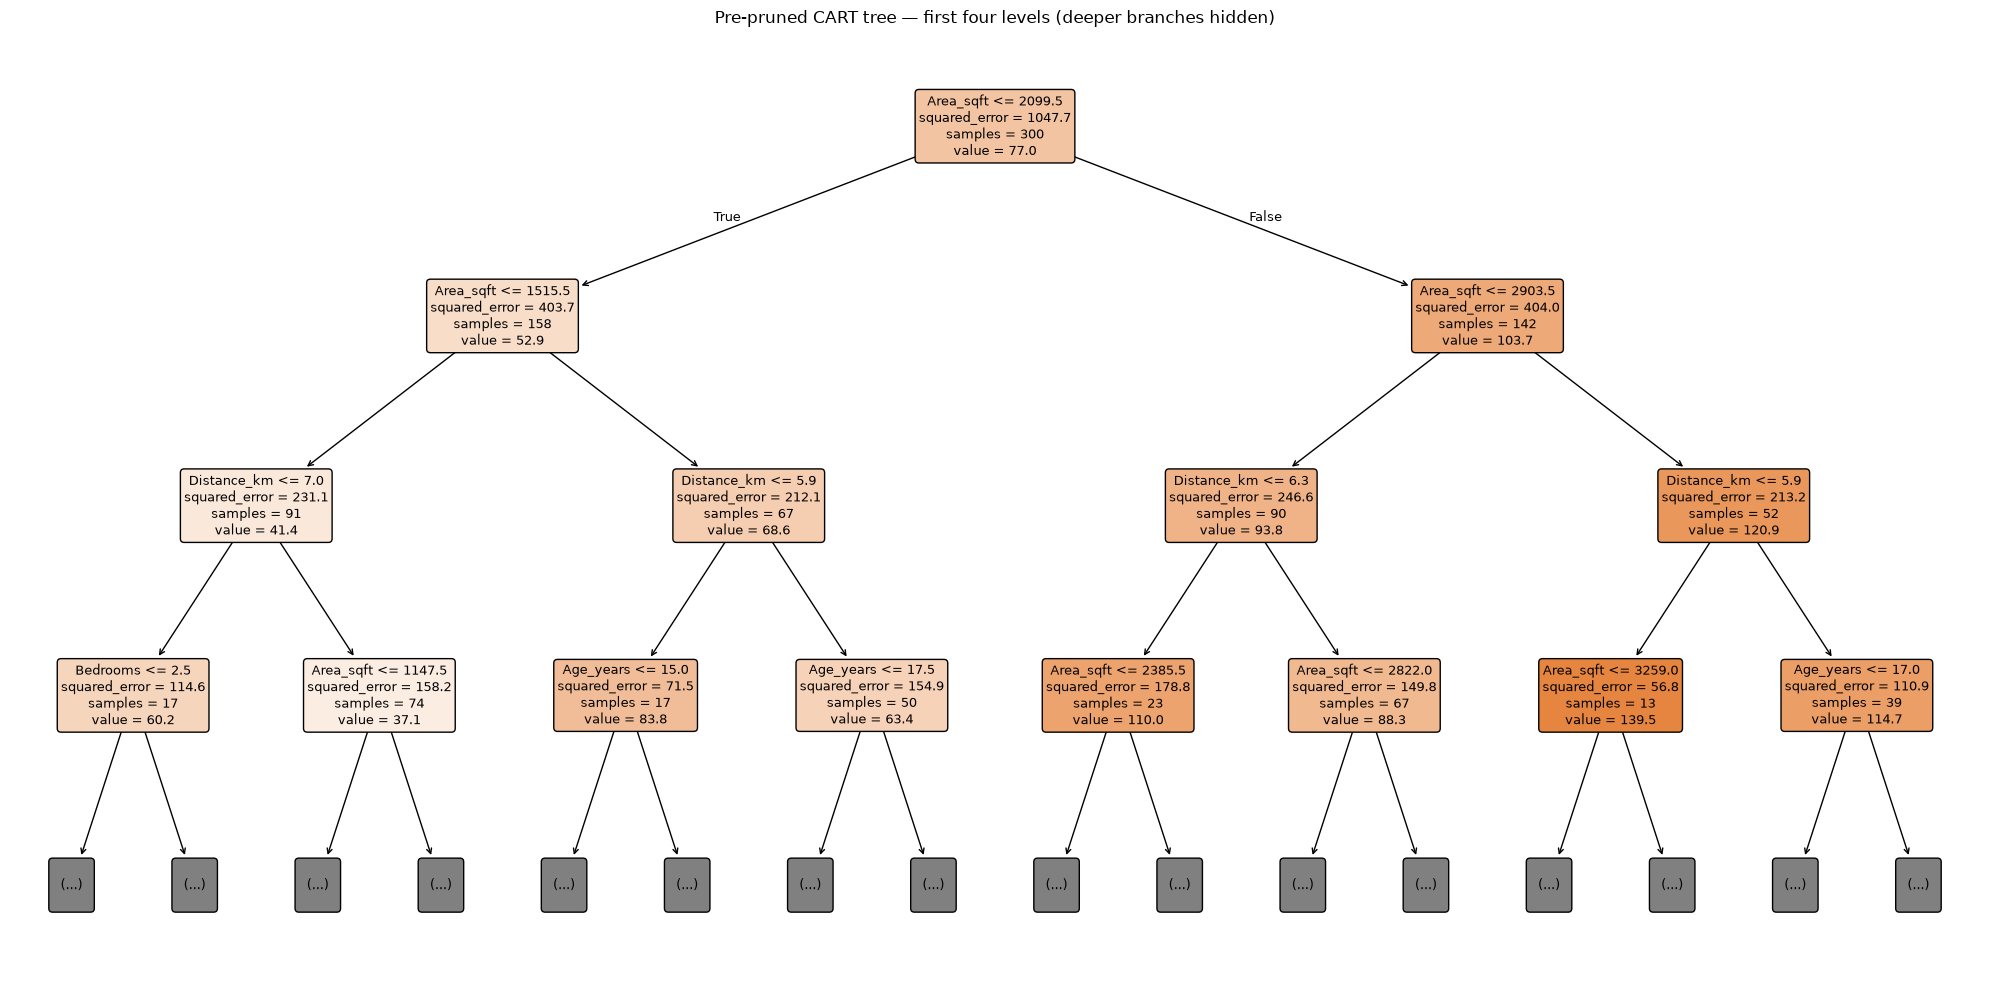

In [42]:
plt.figure(figsize=(20, 10))
plot_tree(reg_pruned_tree, feature_names=reg_X.columns.tolist(), filled=True,
          rounded=True, max_depth=3, precision=1, fontsize=9)
plt.title('Pre-pruned CART tree — first four levels (deeper branches hidden)')
plt.tight_layout()
plt.show()

### 5. Post-pruning: cost-complexity pruning

Cost-complexity pruning balances total weighted leaf impurity against `ccp_alpha × number of leaves`. Increasing alpha favors smaller trees; alpha 0 allows the unrestricted tree. The full-training pruning path illustrates how impurity changes with alpha.

Search a fixed alpha grid with training-only cross-validation so validation-fold targets do not define the candidate grid. Select the alpha with the lowest mean fold MSE. Pruning is not guaranteed to improve test accuracy, and alpha 0 is a valid outcome.

First ten pruning-path alphas: [0.     0.     0.     0.     0.     0.     0.0001 0.0001 0.0001 0.0001]
Selected alpha: 0.3455
Cross-validation RMSE: 11.32
Depth: 11 | Leaves: 76


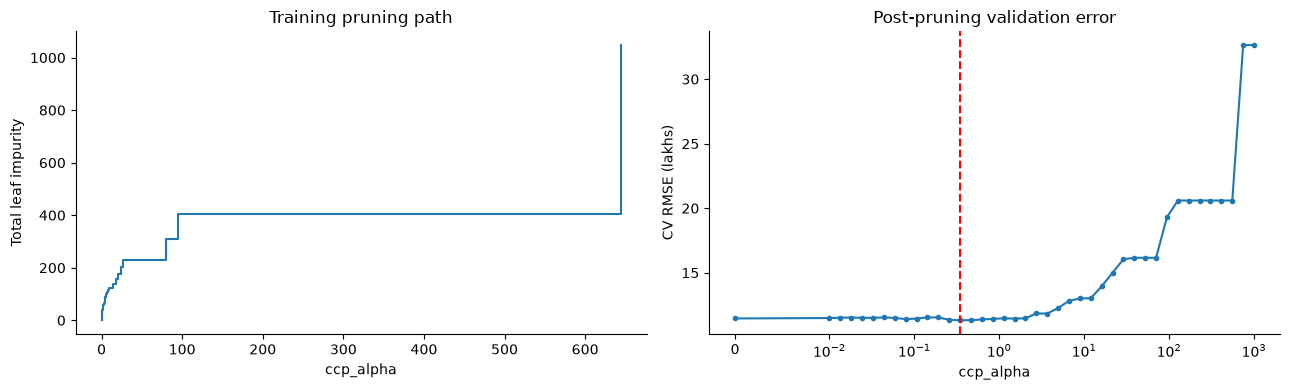

In [43]:
reg_path = reg_full_tree.cost_complexity_pruning_path(reg_X_train, reg_y_train)
print('First ten pruning-path alphas:', np.round(reg_path.ccp_alphas[:10], 4))

reg_alpha_grid = np.r_[0.0, np.logspace(-2, 3, 40)]
reg_post_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid={'ccp_alpha': reg_alpha_grid},
    scoring='neg_mean_squared_error', cv=reg_cv, error_score='raise'
)
reg_post_search.fit(reg_X_train, reg_y_train)
reg_post_pruned_tree = reg_post_search.best_estimator_
print('Selected alpha:', round(reg_post_search.best_params_['ccp_alpha'], 4))
print('Cross-validation RMSE:', round(np.sqrt(-reg_post_search.best_score_), 2))
print('Depth:', reg_post_pruned_tree.get_depth(), '| Leaves:', reg_post_pruned_tree.get_n_leaves())

reg_fig, reg_axes = plt.subplots(1, 2, figsize=(13, 4))
reg_axes[0].step(reg_path.ccp_alphas, reg_path.impurities, where='post')
reg_axes[0].set(xlabel='ccp_alpha', ylabel='Total leaf impurity', title='Training pruning path')
reg_axes[1].plot(reg_alpha_grid, np.sqrt(-reg_post_search.cv_results_['mean_test_score']), marker='.')
reg_axes[1].set_xscale('symlog', linthresh=0.01)
reg_axes[1].axvline(reg_post_search.best_params_['ccp_alpha'], color='red', linestyle='--')
reg_axes[1].set(xlabel='ccp_alpha', ylabel='CV RMSE (lakhs)', title='Post-pruning validation error')
plt.tight_layout()
plt.show()

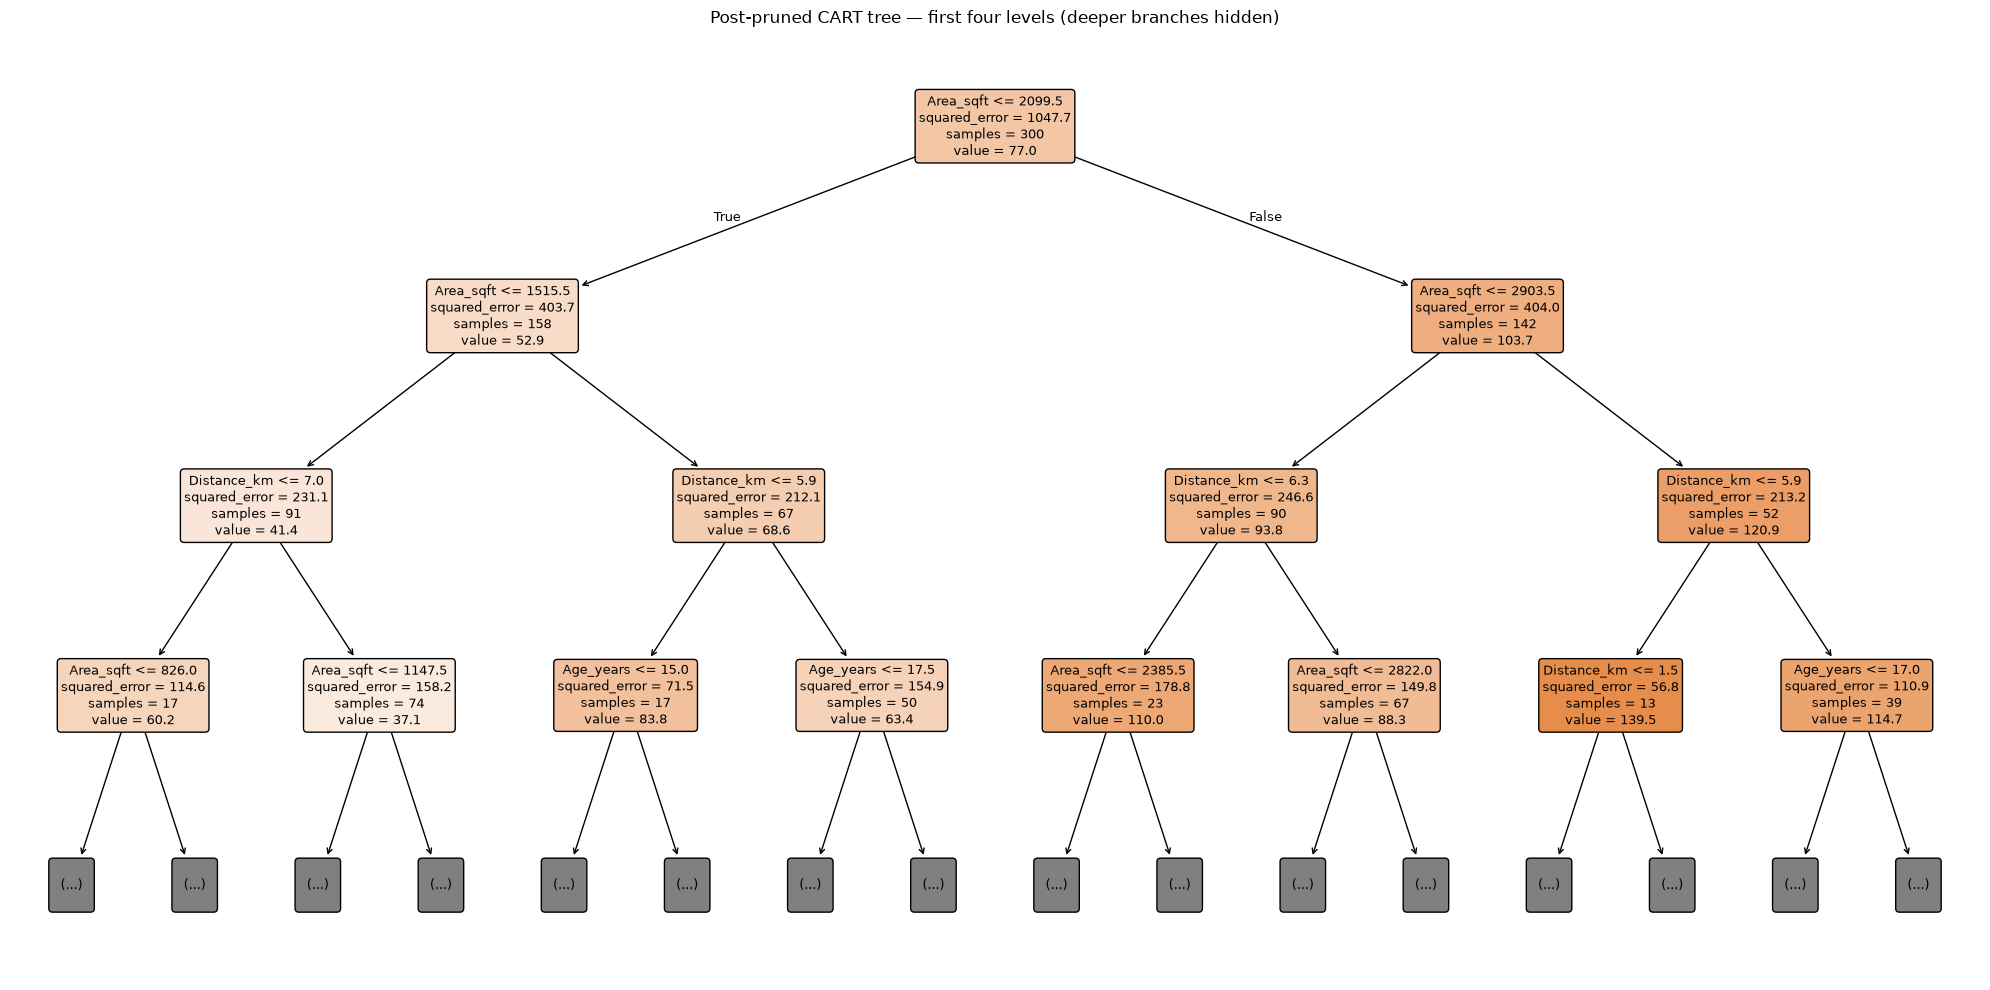

In [44]:
plt.figure(figsize=(20, 10))
plot_tree(reg_post_pruned_tree, feature_names=reg_X.columns.tolist(), filled=True,
          rounded=True, max_depth=3, precision=1, fontsize=9)
plt.title('Post-pruned CART tree — first four levels (deeper branches hidden)')
plt.tight_layout()
plt.show()

### 6. Select by cross-validation, then evaluate on held-out data

Compare the full tree with the best pre-pruned and post-pruned candidates using training CV MSE. Exact ties favor fewer leaves and then lower depth. Freeze this choice before reporting test metrics; do not replace it with whichever model happens to rank first on this test split.

**MAE** is average absolute error; **RMSE** gives larger errors more weight. Both are in lakhs and lower is better. **R²** compares squared error with a constant test-mean reference: higher is better, 1 is perfect, and values can be negative. A baseline fitted to the training mean shows whether the trees learn useful patterns.

Model selected by training cross-validation: Pre-Pruned Tree


,Depth,Leaves,CV RMSE,Train RMSE,Test MAE,Test RMSE,Test R2
Model,,,,,,,
Mean baseline,NaN,NaN,32.636,32.369,28.344,33.289,-0.000
Full Tree,14.0,300.0,11.462,0.000,9.042,11.438,0.882
Pre-Pruned Tree,9.0,48.0,10.819,6.072,9.775,12.563,0.858
Post-Pruned Tree,11.0,76.0,11.320,3.748,9.918,12.013,0.870


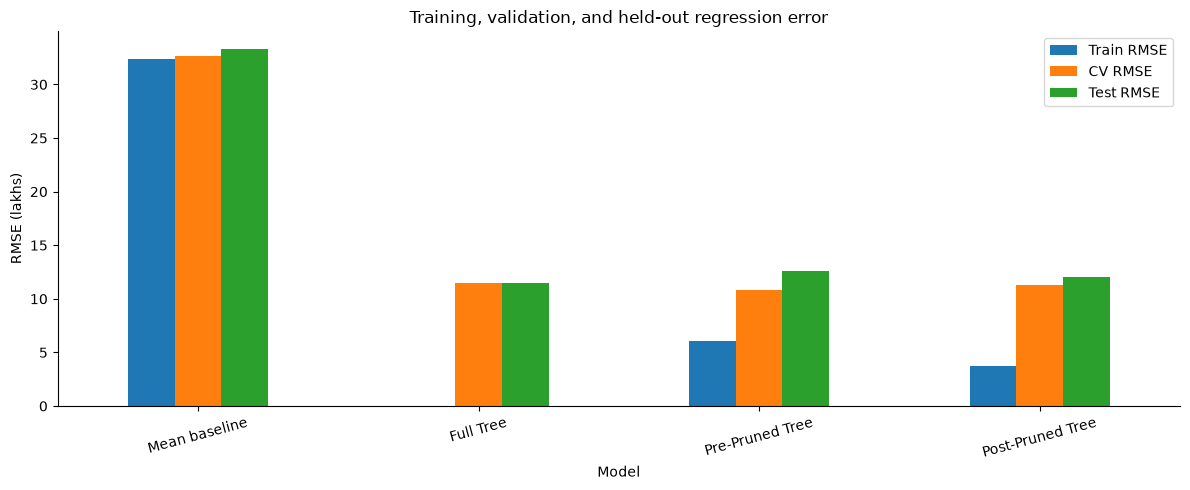

In [45]:
reg_baseline = DummyRegressor(strategy='mean').fit(reg_X_train, reg_y_train)
reg_baseline_cv_mse = -cross_val_score(reg_baseline, reg_X_train, reg_y_train, scoring='neg_mean_squared_error', cv=reg_cv)
reg_models = {'Mean baseline': reg_baseline, 'Full Tree': reg_full_tree,
          'Pre-Pruned Tree': reg_pruned_tree, 'Post-Pruned Tree': reg_post_pruned_tree}
reg_cv_mse = {'Mean baseline': reg_baseline_cv_mse.mean(), 'Full Tree': reg_full_cv_mse.mean(),
          'Pre-Pruned Tree': -reg_pre_search.best_score_, 'Post-Pruned Tree': -reg_post_search.best_score_}
reg_best_model_name = min(
    ['Full Tree', 'Pre-Pruned Tree', 'Post-Pruned Tree'],
    key=lambda reg_name: (reg_cv_mse[reg_name], reg_models[reg_name].get_n_leaves(), reg_models[reg_name].get_depth())
)
reg_best_model = reg_models[reg_best_model_name]
print('Model selected by training cross-validation:', reg_best_model_name)

reg_rows = []
for reg_name, reg_model in reg_models.items():
    reg_train_pred = reg_model.predict(reg_X_train)
    reg_test_pred = reg_model.predict(reg_X_test)
    reg_rows.append({
        'Model': reg_name,
        'Depth': reg_model.get_depth() if hasattr(reg_model, 'get_depth') else np.nan,
        'Leaves': reg_model.get_n_leaves() if hasattr(reg_model, 'get_n_leaves') else np.nan,
        'CV RMSE': np.sqrt(reg_cv_mse[reg_name]),
        'Train RMSE': np.sqrt(mean_squared_error(reg_y_train, reg_train_pred)),
        'Test MAE': mean_absolute_error(reg_y_test, reg_test_pred),
        'Test RMSE': np.sqrt(mean_squared_error(reg_y_test, reg_test_pred)),
        'Test R2': r2_score(reg_y_test, reg_test_pred),
    })
reg_comparison = pd.DataFrame(reg_rows).set_index('Model')
display(reg_comparison.round(3))
reg_comparison[['Train RMSE', 'CV RMSE', 'Test RMSE']].plot.bar(
    figsize=(12, 5), rot=15, title='Training, validation, and held-out regression error'
)
plt.ylabel('RMSE (lakhs)')
plt.tight_layout()
plt.show()

### 7. Inspect predictions, residuals, and feature importance

Residual = actual price minus predicted price: positive residuals mean underprediction. Predictions near the diagonal in the first plot are accurate. A residual plot centered around zero without a strong pattern is desirable; structured patterns can reveal relationships the tree misses.

Impurity importance sums the weighted error reductions attributable to each feature. It describes this fitted tree, can favor features with more possible splits, and does not establish causation.

,Area_sqft,Bedrooms,Age_years,Distance_km,Actual_price,Predicted_price,Residual
209,2859,5,16,24.8,91.90,109.75,-17.85
280,1400,4,28,10.8,41.20,54.19,-12.99
33,2208,1,4,9.9,81.70,81.83,-0.13
210,1357,5,8,1.1,92.12,68.48,23.64
93,1724,4,30,8.8,62.01,65.17,-3.16
84,2426,3,25,16.2,76.45,75.08,1.37
329,2209,4,20,18.6,66.12,90.72,-24.60
94,3205,2,23,22.8,101.29,98.28,3.02
266,1896,3,28,21.8,50.83,48.57,2.26
126,829,5,16,6.9,47.04,61.69,-14.65


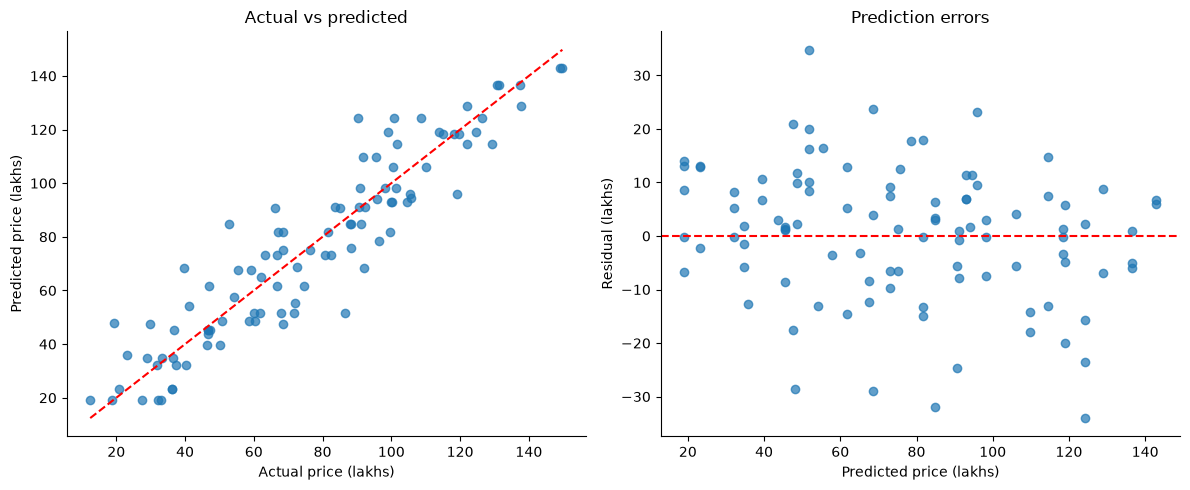

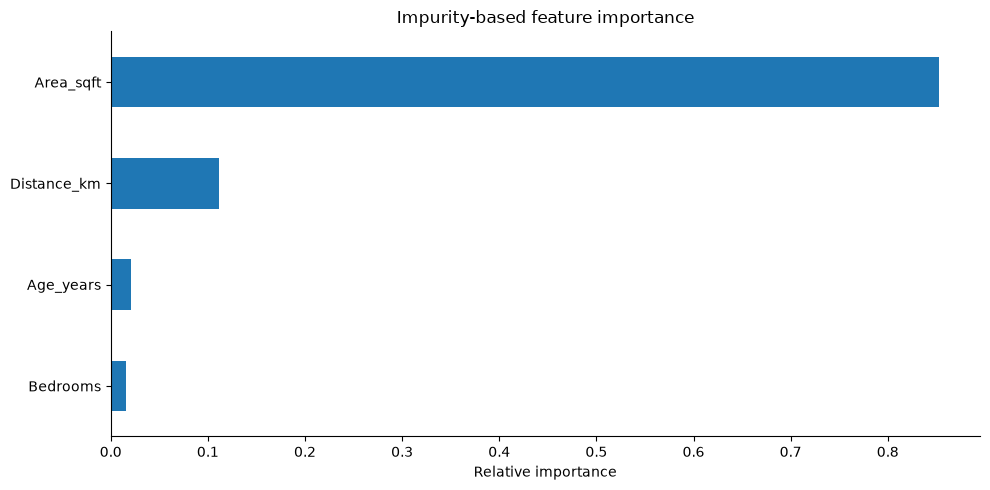

In [46]:
reg_predictions = reg_best_model.predict(reg_X_test)
reg_results = reg_X_test.copy()
reg_results['Actual_price'] = reg_y_test
reg_results['Predicted_price'] = reg_predictions
reg_results['Residual'] = reg_results['Actual_price'] - reg_results['Predicted_price']
display(reg_results.head(10).round(2))

reg_fig, reg_axes = plt.subplots(1, 2, figsize=(12, 5))
reg_axes[0].scatter(reg_y_test, reg_predictions, alpha=0.7)
reg_limits = [min(reg_y_test.min(), reg_predictions.min()), max(reg_y_test.max(), reg_predictions.max())]
reg_axes[0].plot(reg_limits, reg_limits, 'r--')
reg_axes[0].set(xlabel='Actual price (lakhs)', ylabel='Predicted price (lakhs)', title='Actual vs predicted')
reg_axes[1].scatter(reg_predictions, reg_y_test - reg_predictions, alpha=0.7)
reg_axes[1].axhline(0, color='red', linestyle='--')
reg_axes[1].set(xlabel='Predicted price (lakhs)', ylabel='Residual (lakhs)', title='Prediction errors')
plt.tight_layout()
plt.show()

reg_importance = pd.Series(reg_best_model.feature_importances_, index=reg_X.columns).sort_values()
reg_importance.plot.barh(title='Impurity-based feature importance')
plt.xlabel('Relative importance')
plt.tight_layout()
plt.show()

### 8. Predict a new house and explain the prediction

Supply feature values in the same units and column order as training. This hypothetical house has no observed target, so its prediction is a demonstration rather than an accuracy check. The tree predicts the mean price of training houses in the reached leaf; it cannot smoothly extrapolate outside the training target range.

The tree rules below include the full selected model, even though the diagrams hide deeper branches for readability.

In [47]:
reg_new_house = pd.DataFrame({
    'Area_sqft': [1800], 'Bedrooms': [3], 'Age_years': [5], 'Distance_km': [8.0]
})
display(reg_new_house)
print(f'Predicted house price: {reg_best_model.predict(reg_new_house)[0]:.2f} lakhs')
print('Selected tree rules:')
print(export_text(reg_best_model, feature_names=reg_X.columns.tolist(), decimals=2))
reg_leaf_id = reg_best_model.apply(reg_new_house)[0]
reg_training_leaf_ids = reg_best_model.apply(reg_X_train)
reg_leaf_targets = reg_y_train.loc[reg_training_leaf_ids == reg_leaf_id]
print('Training houses in the reached leaf:', len(reg_leaf_targets))
print(f'Mean training price in this leaf: {reg_leaf_targets.mean():.2f} lakhs')
assert np.isclose(reg_best_model.predict(reg_new_house)[0], reg_leaf_targets.mean())

,Area_sqft,Bedrooms,Age_years,Distance_km
0,1800,3,5,8.0


Predicted house price: 67.58 lakhs
Selected tree rules:
|--- Area_sqft <= 2099.50
|   |--- Area_sqft <= 1515.50
|   |   |--- Distance_km <= 6.95
|   |   |   |--- Bedrooms <= 2.50
|   |   |   |   |--- value: [51.69]
|   |   |   |--- Bedrooms >  2.50
|   |   |   |   |--- Area_sqft <= 1118.00
|   |   |   |   |   |--- value: [61.69]
|   |   |   |   |--- Area_sqft >  1118.00
|   |   |   |   |   |--- value: [68.48]
|   |   |--- Distance_km >  6.95
|   |   |   |--- Area_sqft <= 1147.50
|   |   |   |   |--- Area_sqft <= 749.50
|   |   |   |   |   |--- value: [19.05]
|   |   |   |   |--- Area_sqft >  749.50
|   |   |   |   |   |--- Distance_km <= 21.70
|   |   |   |   |   |   |--- Age_years <= 12.50
|   |   |   |   |   |   |   |--- Distance_km <= 11.95
|   |   |   |   |   |   |   |   |--- value: [43.66]
|   |   |   |   |   |   |   |--- Distance_km >  11.95
|   |   |   |   |   |   |   |   |--- Bedrooms <= 3.50
|   |   |   |   |   |   |   |   |   |--- value: [34.76]
|   |   |   |   |   |   |   | 

### 9. Conclusions from this run

The summary below uses the executed results. A model selected by cross-validation can be outperformed by another model on a particular test split because validation and test samples differ. That is a reason to report both honestly, not to select again using the test set.

In [48]:
reg_selected = reg_comparison.loc[reg_best_model_name]
reg_test_leader = reg_comparison['Test RMSE'].idxmin()
print('Selected model:', reg_best_model_name)
print(f'Depth: {reg_best_model.get_depth()} | Leaves: {reg_best_model.get_n_leaves()}')
print(f'CV RMSE: {reg_selected["CV RMSE"]:.2f} lakhs')
print(f'Test MAE: {reg_selected["Test MAE"]:.2f} lakhs')
print(f'Test RMSE: {reg_selected["Test RMSE"]:.2f} lakhs')
print(f'Test R²: {reg_selected["Test R2"]:.3f}')
print(f'Average absolute error on these synthetic test houses: {reg_selected["Test MAE"]:.2f} lakhs.')
print('Lowest test RMSE in the comparison:', reg_test_leader)
if reg_test_leader != reg_best_model_name:
    print('The test ranking differs from cross-validation; we retain the CV-selected model.')
else:
    print('The selected model also has the lowest test RMSE in this comparison.')
reg_improvement = 100 * (1 - reg_selected['Test RMSE'] / reg_comparison.loc['Mean baseline', 'Test RMSE'])
print(f'Test RMSE reduction relative to the mean baseline: {reg_improvement:.1f}%')
assert len(reg_predictions) == len(reg_y_test)
assert np.isfinite(reg_predictions).all()
assert reg_best_model.n_features_in_ == reg_X.shape[1]
print('Workflow checks passed.')

Selected model: Pre-Pruned Tree
Depth: 9 | Leaves: 48
CV RMSE: 10.82 lakhs
Test MAE: 9.77 lakhs
Test RMSE: 12.56 lakhs
Test R²: 0.858
Average absolute error on these synthetic test houses: 9.77 lakhs.
Lowest test RMSE in the comparison: Full Tree
The test ranking differs from cross-validation; we retain the CV-selected model.
Test RMSE reduction relative to the mean baseline: 62.3%
Workflow checks passed.


#### Key takeaways and limitations

- The full tree can memorize training observations. Use validation and test errors to assess whether that fit generalizes.
- Pre-pruning restricts growth; post-pruning penalizes complexity. Neither guarantees a lower test error.
- All model selection in this final workflow uses training cross-validation. Test results are evaluation and interpretation only.
- This test split has already been inspected during notebook development, so it is not a completely untouched external benchmark. New independent data or nested cross-validation would support stronger performance claims.
- The data follow a deliberately constructed simulation. Results do not validate a model for actual property valuation; a real application requires representative data and appropriate validation.
- Tree predictions are constant within leaves and do not extrapolate smoothly. Feature importance is not causal evidence.
- The notebook is self-contained: run cells in order with NumPy, pandas, matplotlib, scikit-learn, and IPython installed. Dataset generation and model fitting use fixed random seeds; package versions can still affect numerical details.

<a id="cart-comparison"></a>
## CART comparison

| Aspect | Classification | Regression |
|---|---|---|
| Example | Wine cultivar | Synthetic house price |
| Target | One of three classes | Numeric price in lakhs |
| Estimator | `DecisionTreeClassifier` | `DecisionTreeRegressor` |
| Split criterion | Gini impurity | Squared error |
| Leaf prediction | Majority class, with class proportions | Mean training target in the leaf |
| Model selection | Highest CV balanced accuracy | Lowest CV mean squared error |
| Held-out metrics | Accuracy, balanced accuracy, macro F1, log loss | MAE, RMSE, R² |
| Selected model | `clf_best_model` | `reg_best_model` |
| Results table | `clf_comparison` | `reg_comparison` |

Both workflows use binary splits, compare full and pruned trees, and choose hyperparameters using training data only. Their evaluation metrics have different meanings and should not be compared numerically across tasks. The regression data are simulated; their results do not establish real-world valuation accuracy.
